In [1]:
import os
import pandas as pd
from sqlalchemy import create_engine

SAMPLE_SIZE = 10_000  # seguro para la memoria disponible

db_url = (
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:"
    f"{os.environ['POSTGRES_PASSWORD']}@postgres:5432/"
    f"{os.environ['POSTGRES_DB']}"
)
engine = create_engine(db_url)

gold_baseline = pd.read_sql(
    "SELECT * FROM gold.property_training_features LIMIT %(limit)s",
    engine,
    params={"limit": SAMPLE_SIZE},
)

print(f"Filas: {gold_baseline.shape[0]:,} | Columnas: {gold_baseline.shape[1]}")
gold_baseline.head()

Filas: 10,000 | Columnas: 15


,clean_id,batch_id,target_price,brokered_by,status,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_year,prepared_at
0,78719,group-5-batch-4,448900.0,52777.0,for_sale,3.0,2.0,0.26,876056.0,Lonsdale,Minnesota,55046.0,3330.0,2004,2026-11-15 21:30:31.878189+00:00
1,78720,group-5-batch-4,356900.0,57847.0,for_sale,3.0,2.0,0.16,831243.0,Lonsdale,Minnesota,55046.0,2895.0,2018,2026-11-15 21:30:31.878189+00:00
2,78721,group-5-batch-4,354900.0,57847.0,for_sale,3.0,2.0,0.16,932105.0,Lonsdale,Minnesota,55046.0,2895.0,2018,2026-11-15 21:30:31.878189+00:00
3,78722,group-5-batch-4,356900.0,57847.0,for_sale,3.0,2.0,0.16,795398.0,Lonsdale,Minnesota,55046.0,2895.0,2017,2026-11-15 21:30:31.878189+00:00
4,78723,group-5-batch-4,449950.0,12874.0,for_sale,3.0,2.0,0.32,717193.0,Madison Lake,Minnesota,56063.0,1807.0,2022,2026-11-15 21:30:31.878189+00:00


Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)



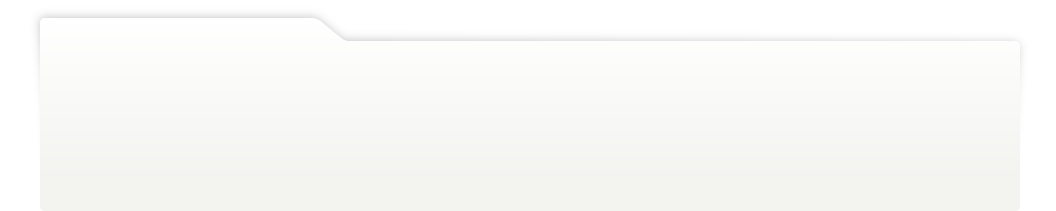
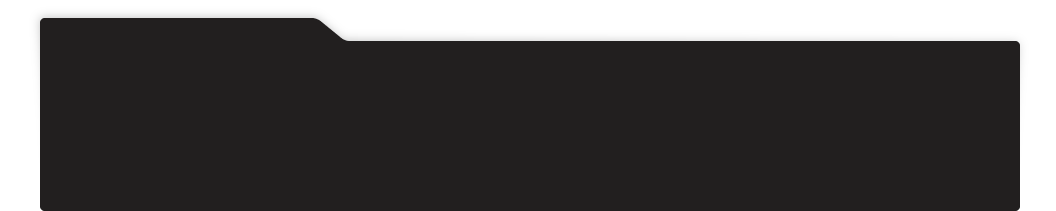
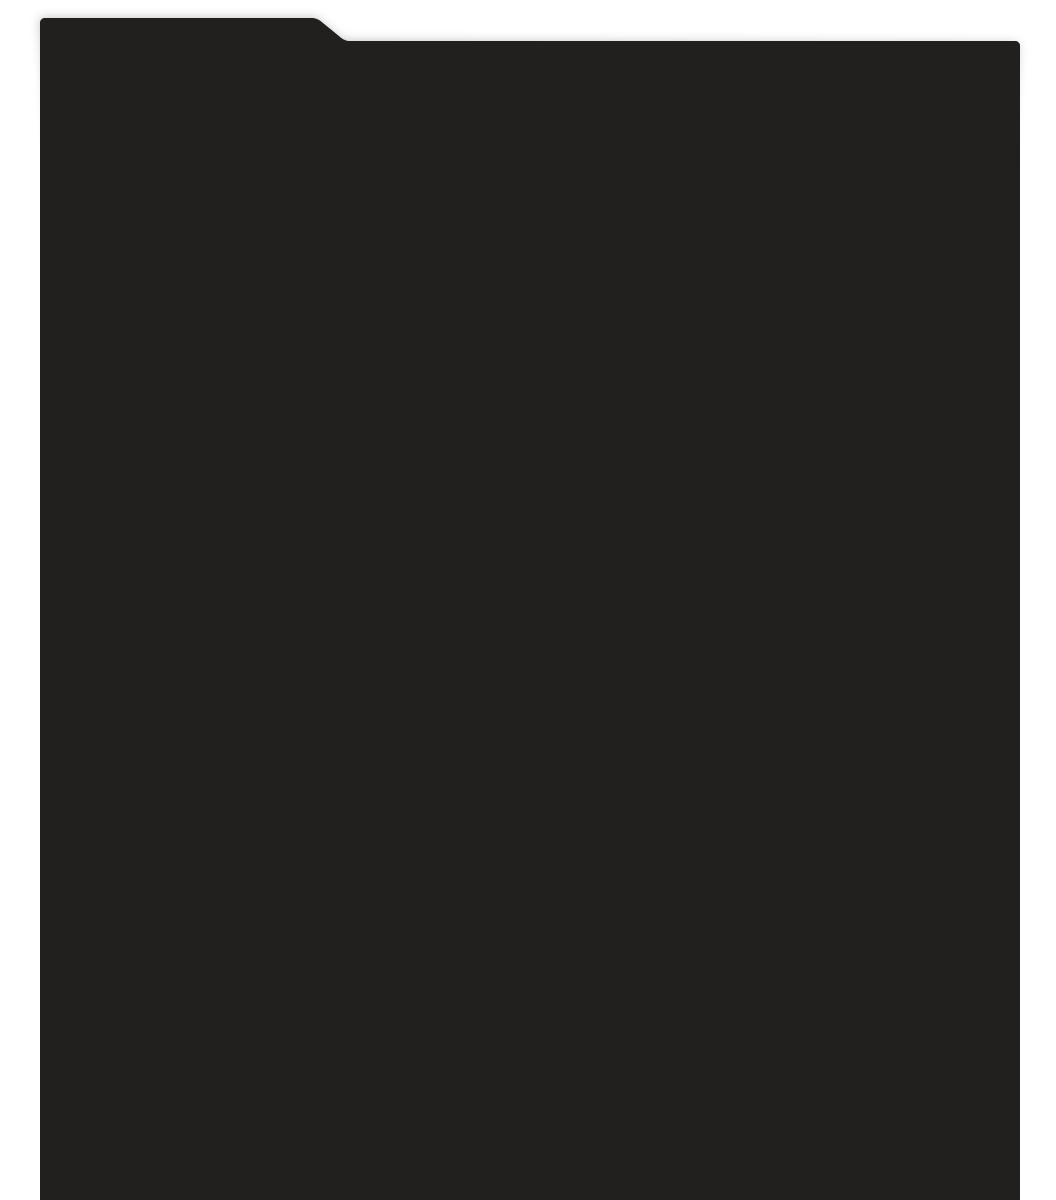
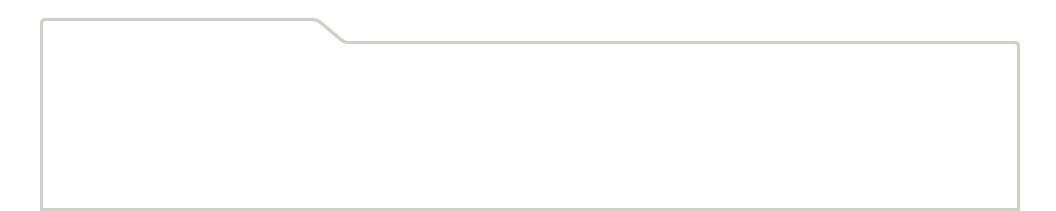
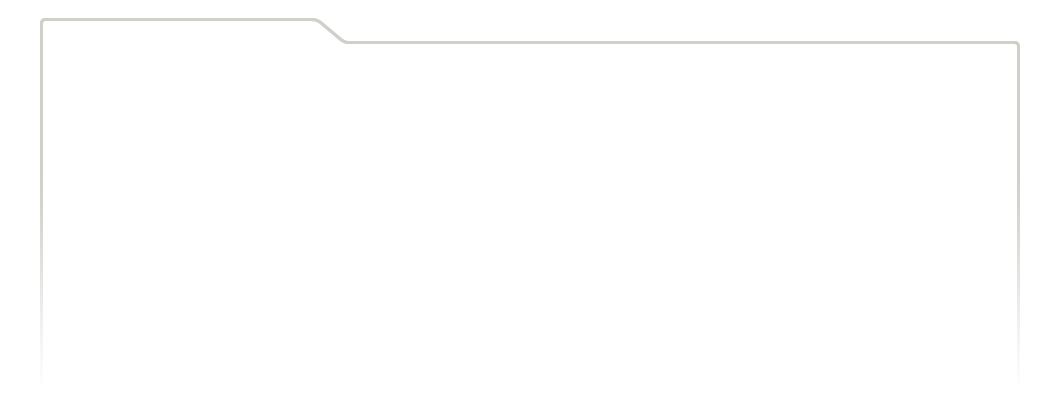
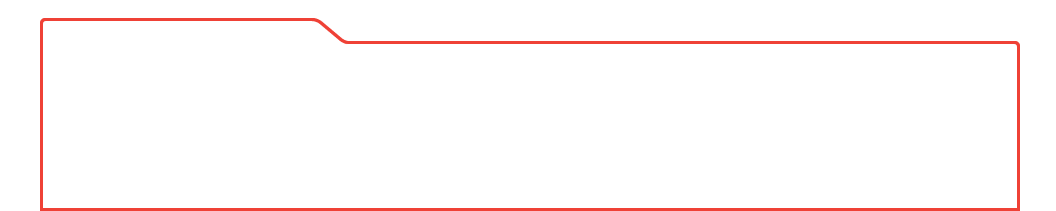
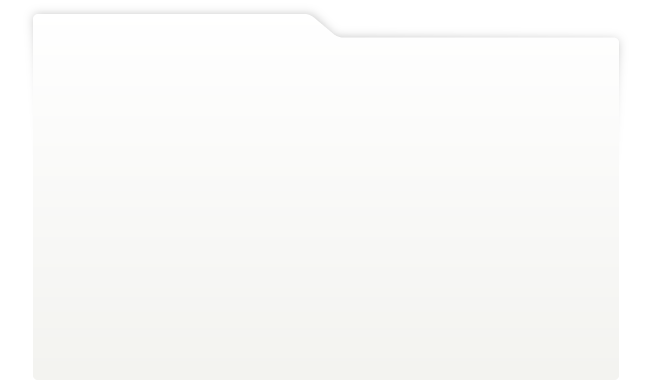
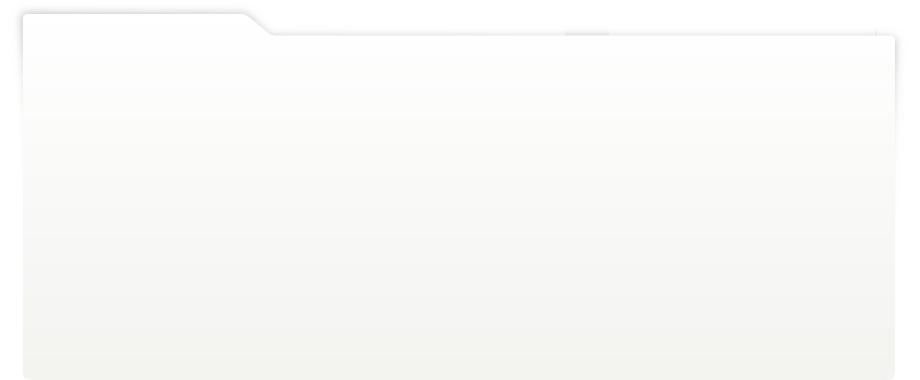
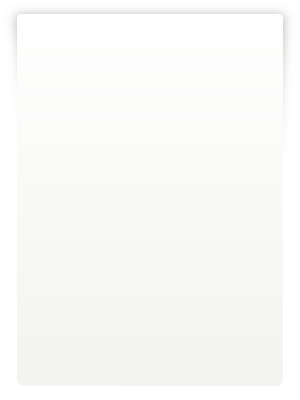
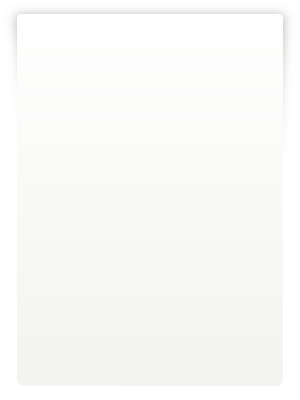
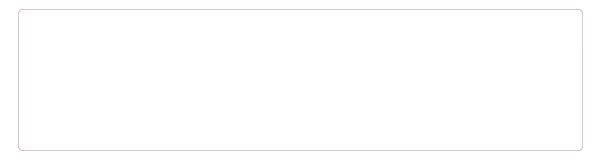
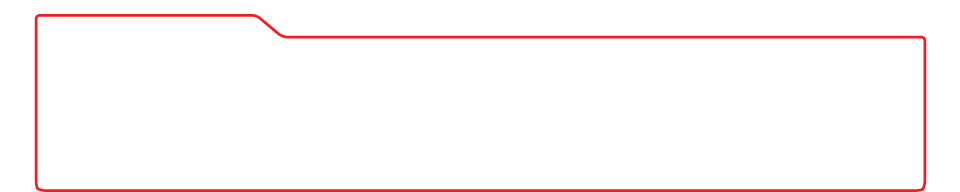
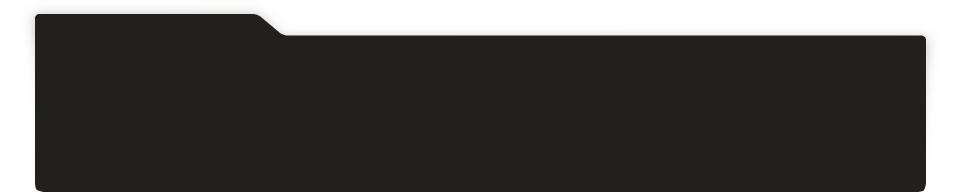
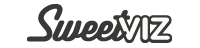
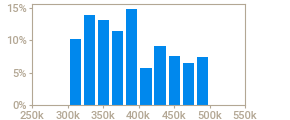
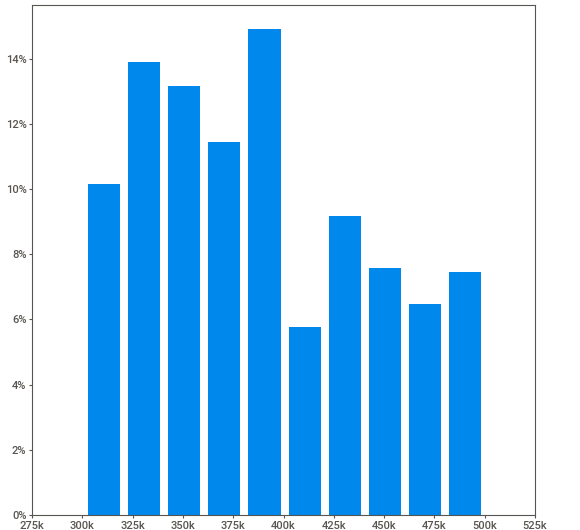
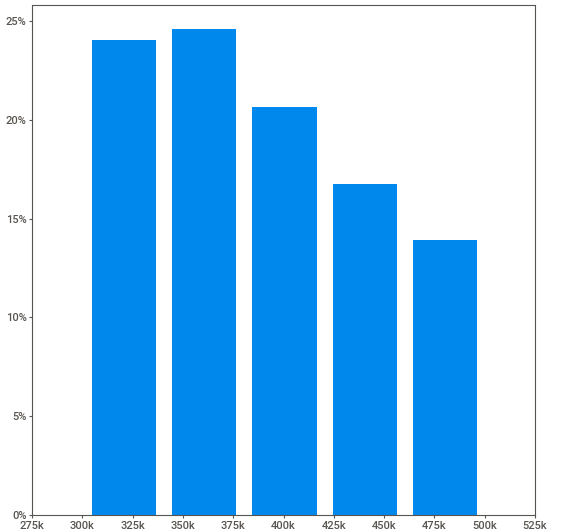
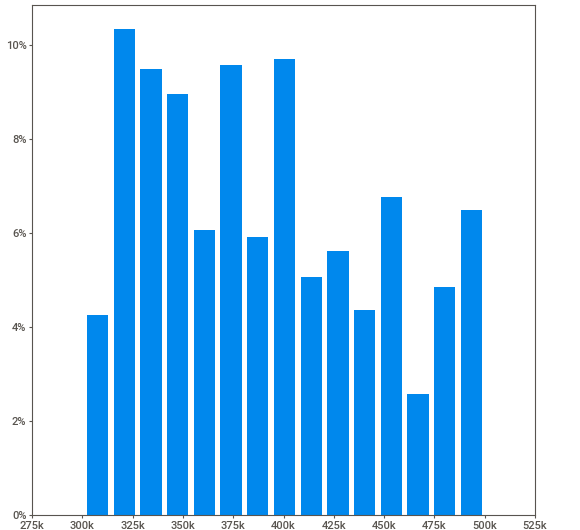
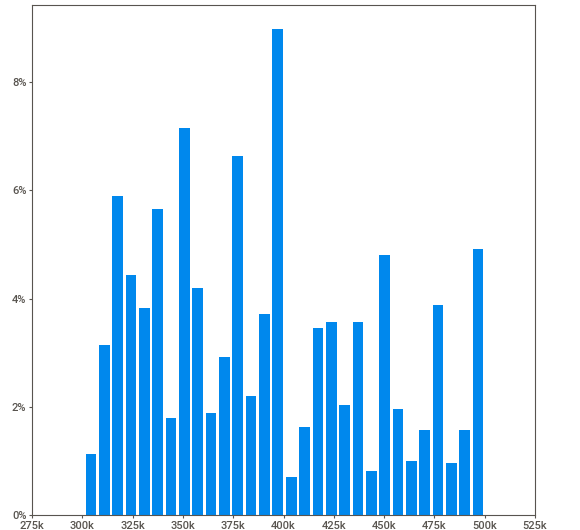
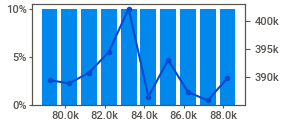
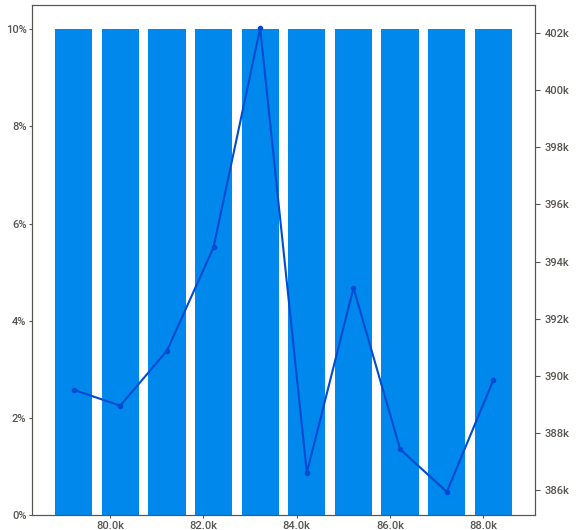
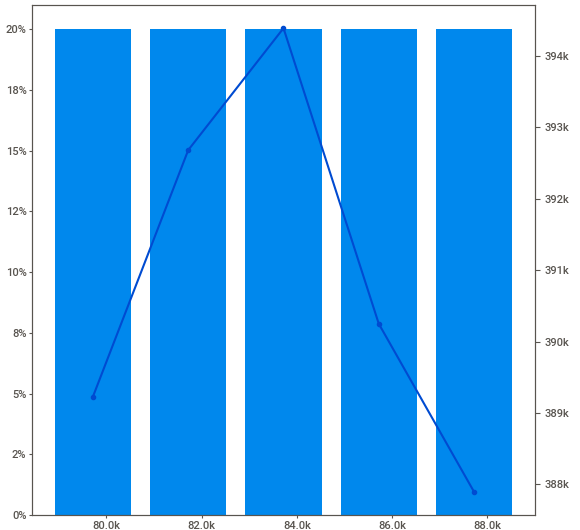
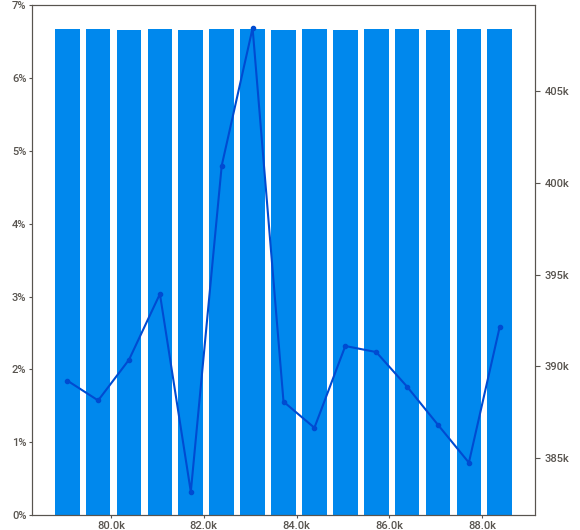
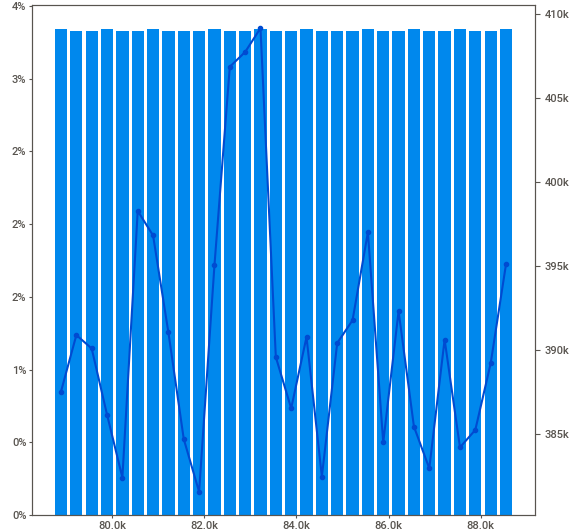
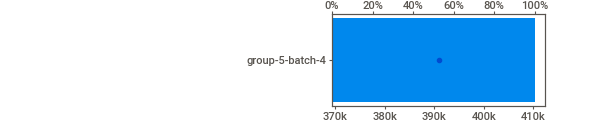
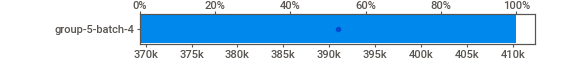
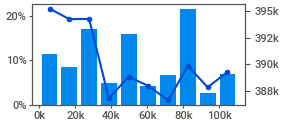
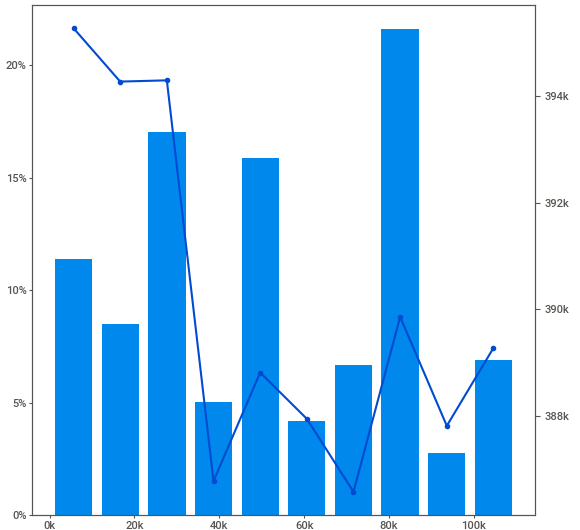
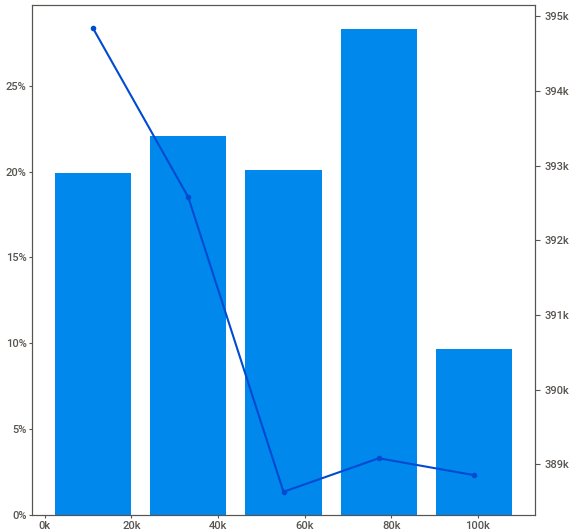
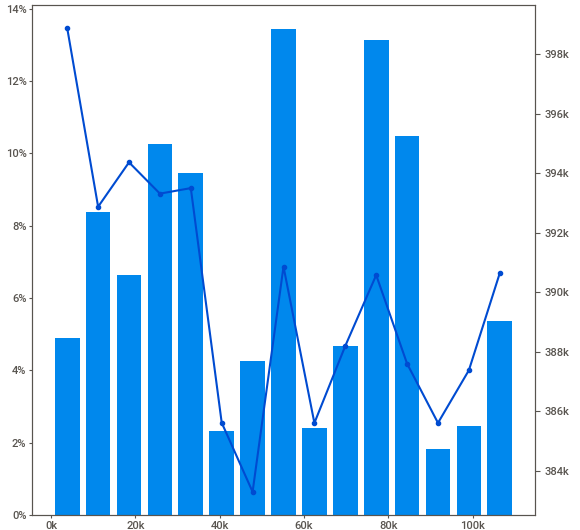
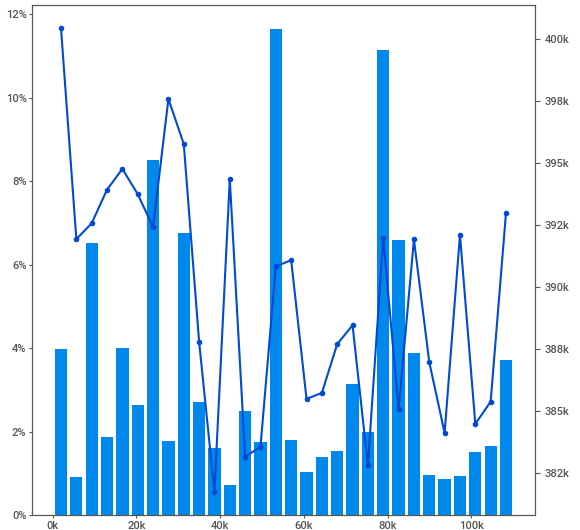
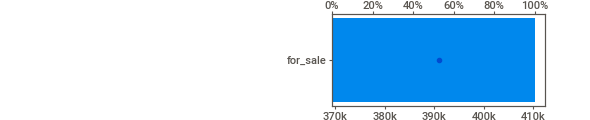
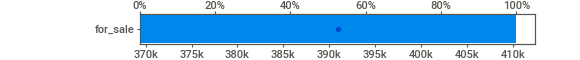
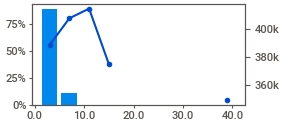
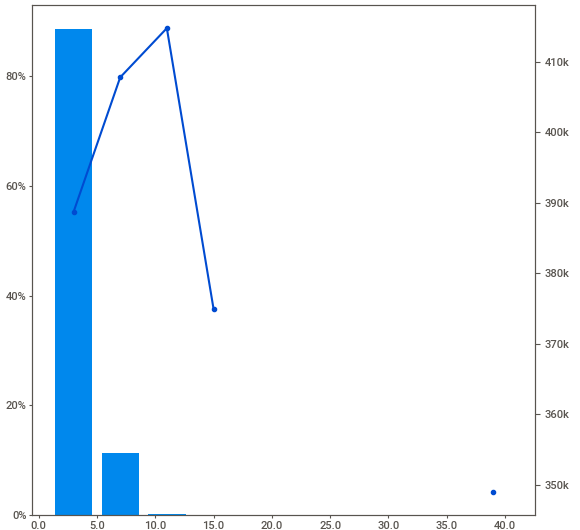
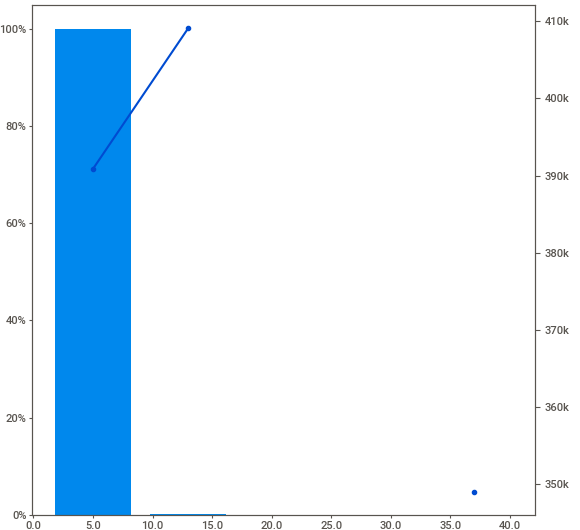
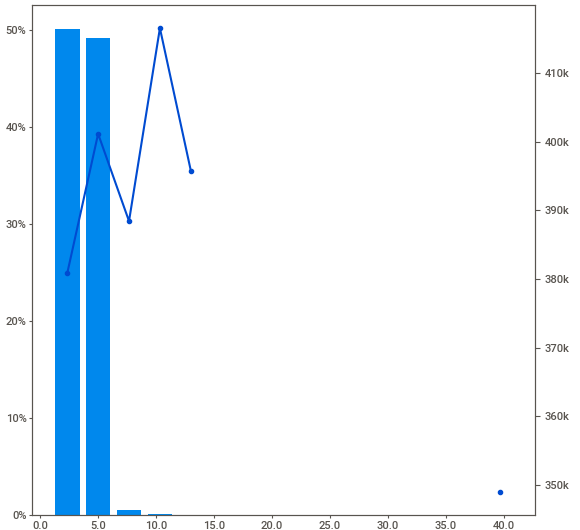
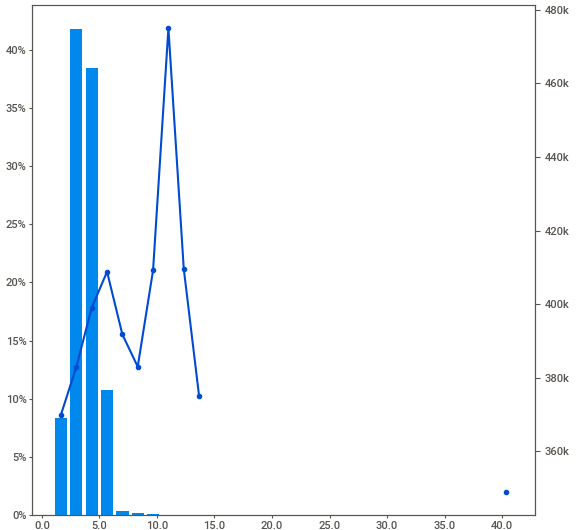
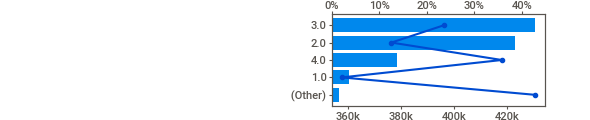
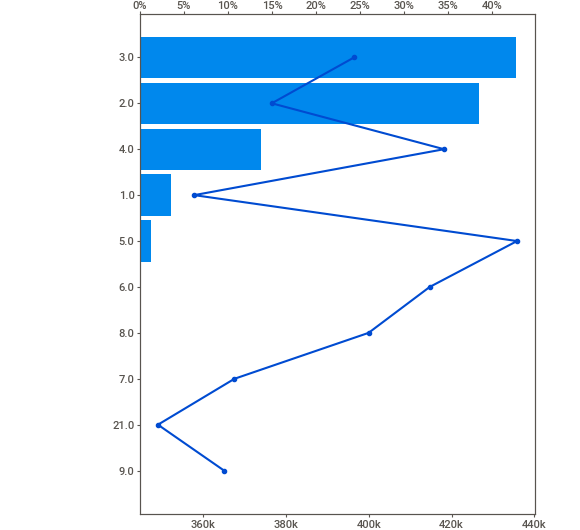
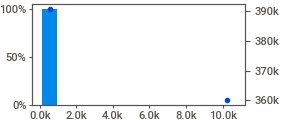
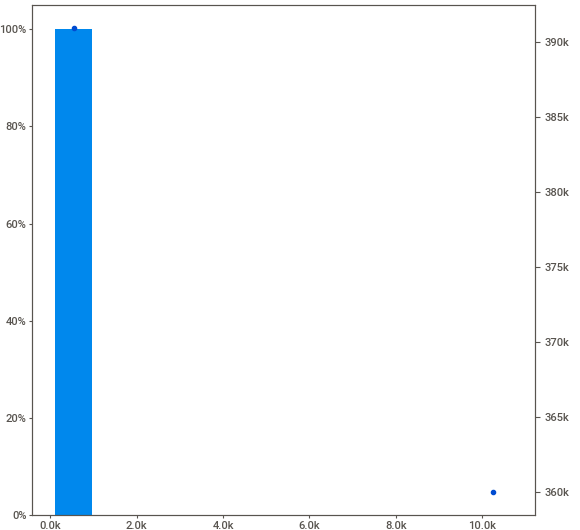
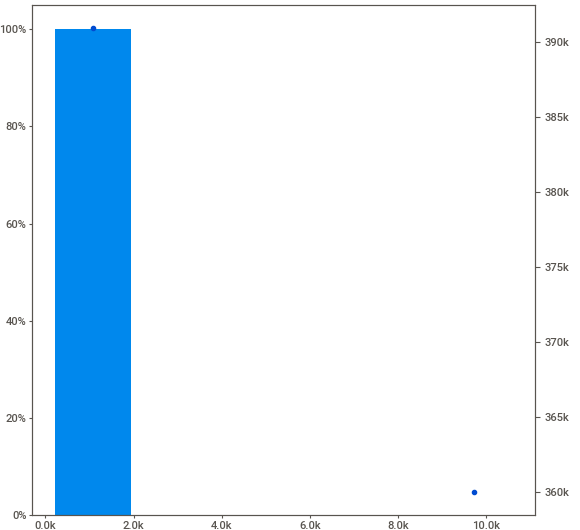
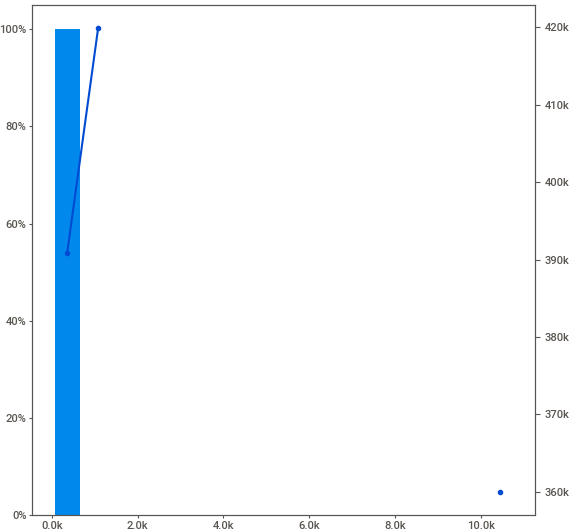
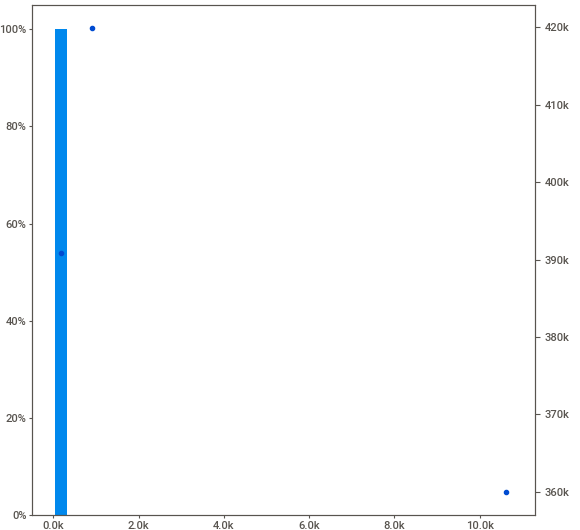
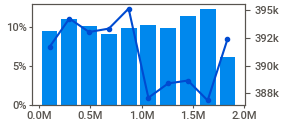
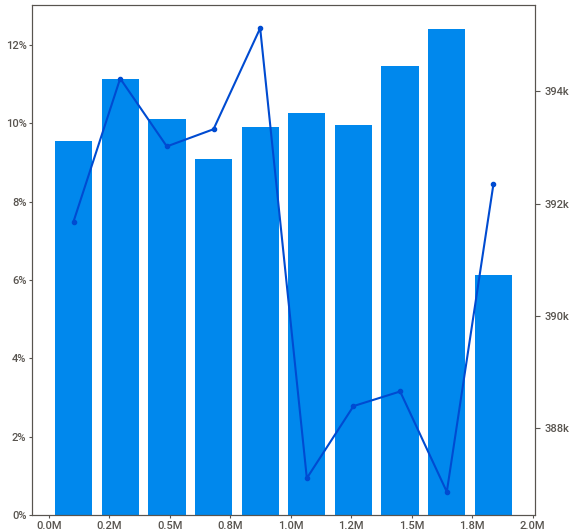
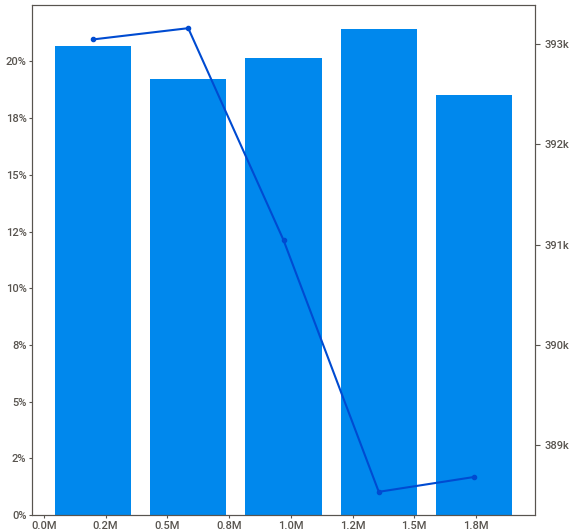
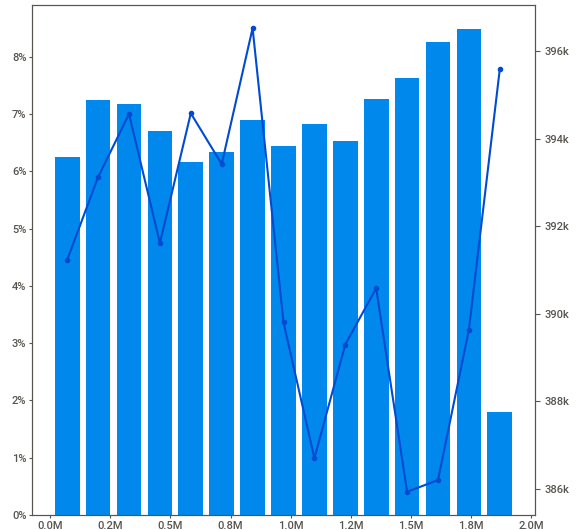
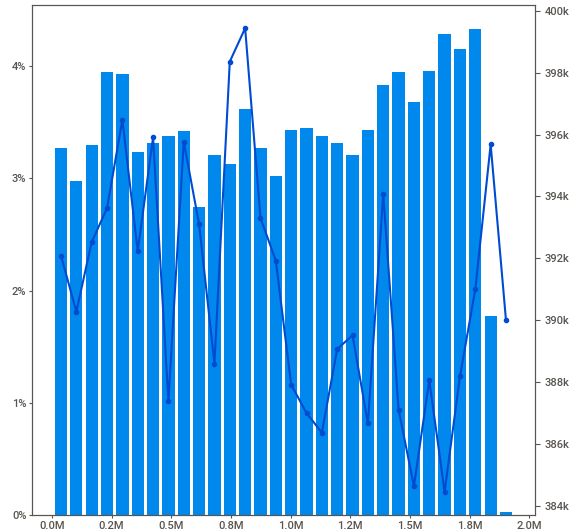
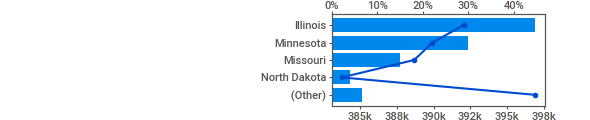
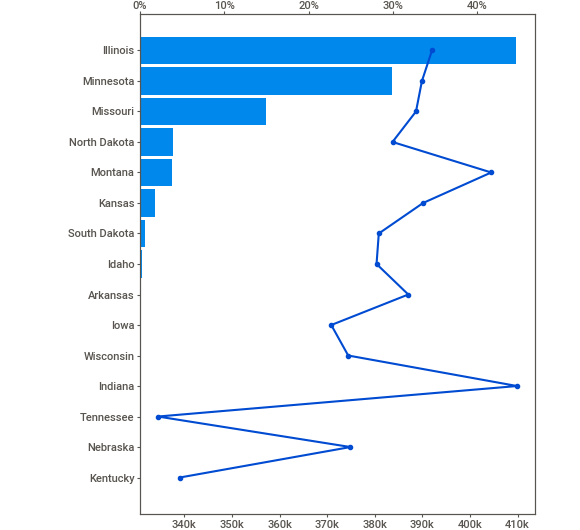
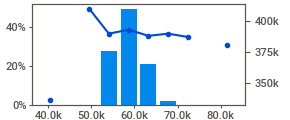
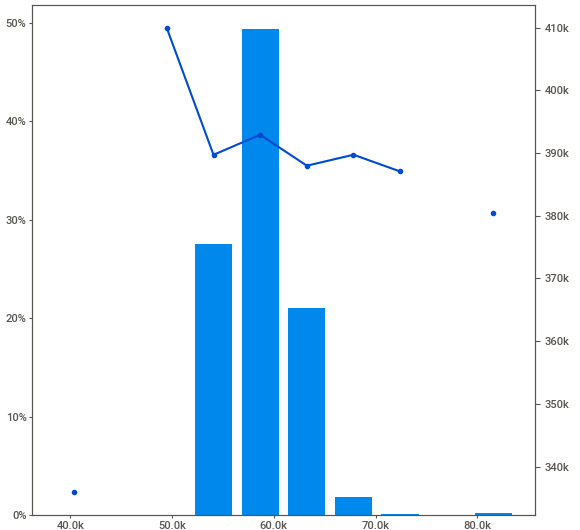
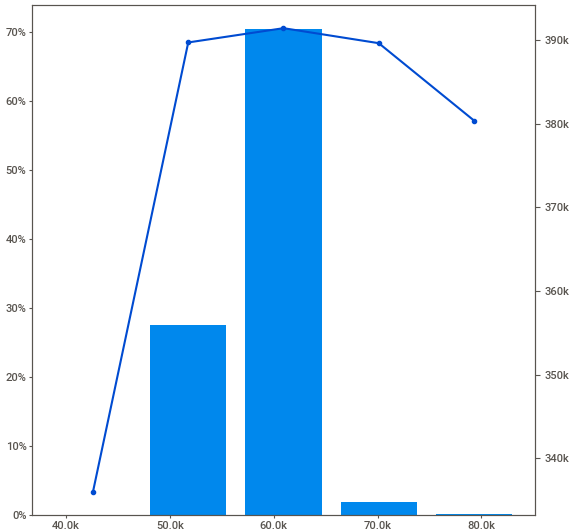
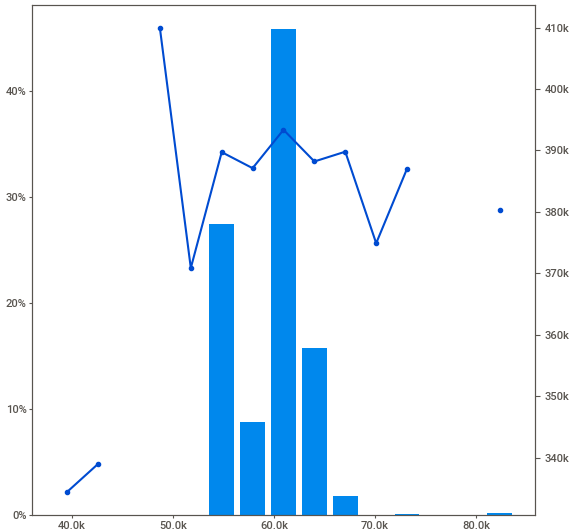
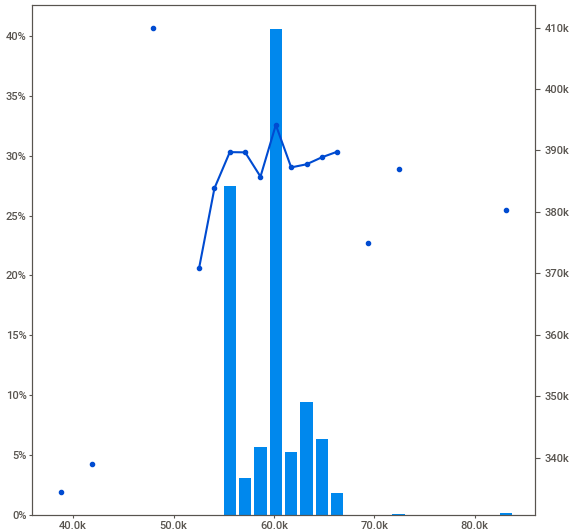
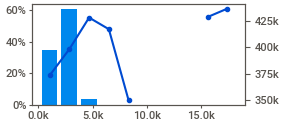
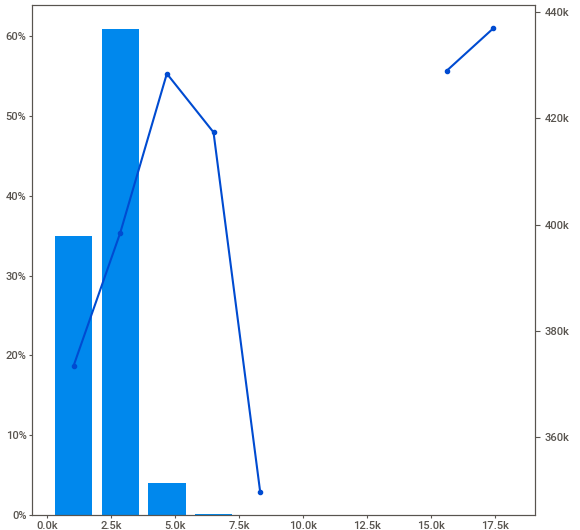
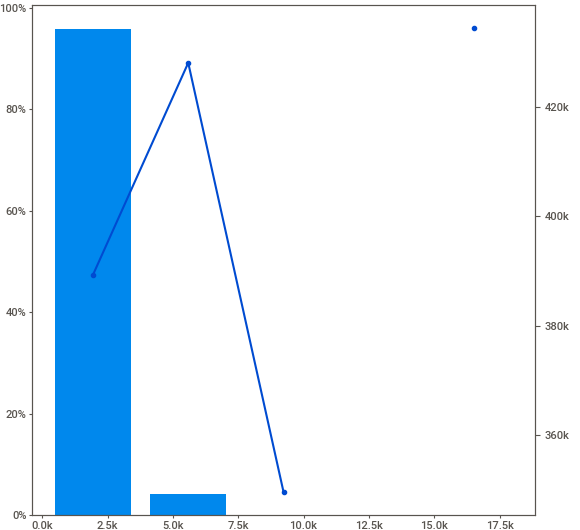
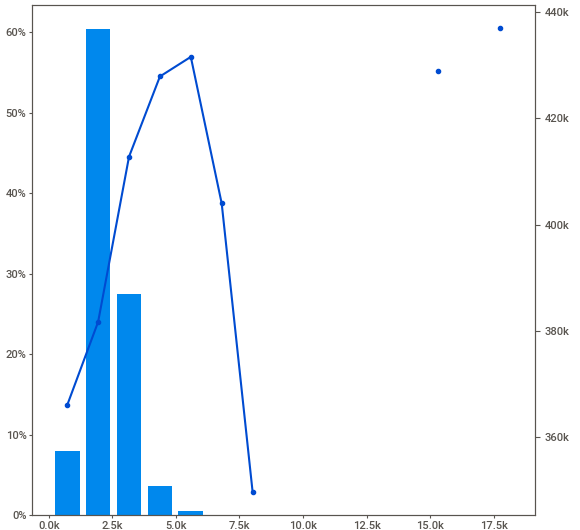
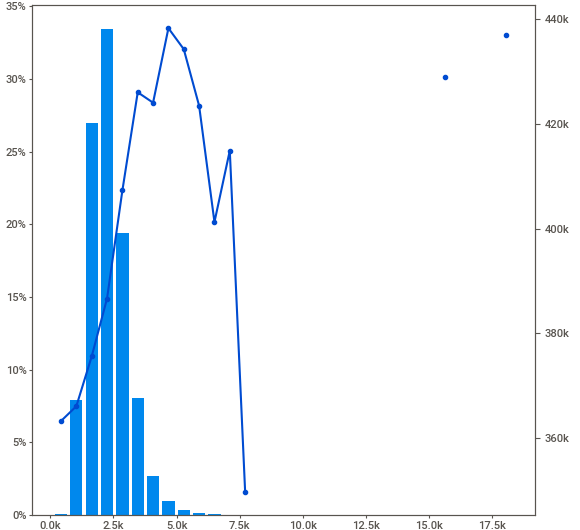
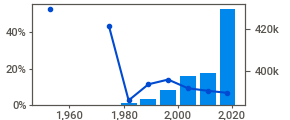
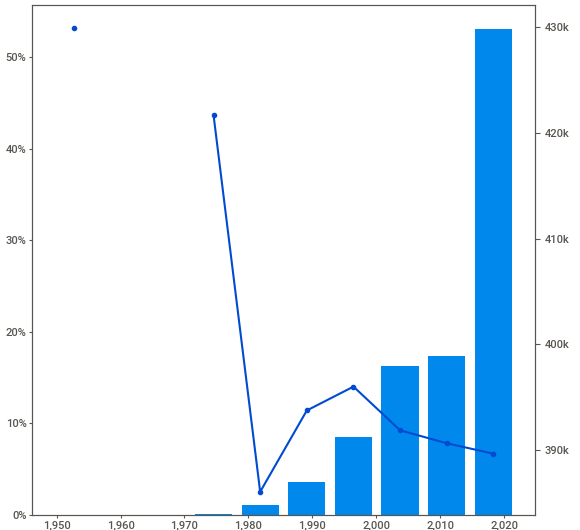
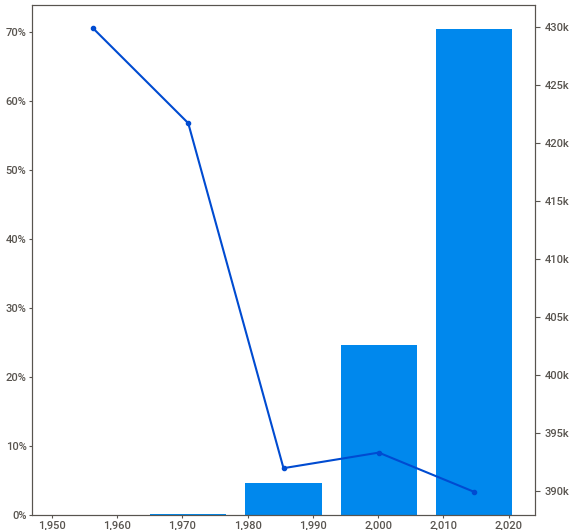
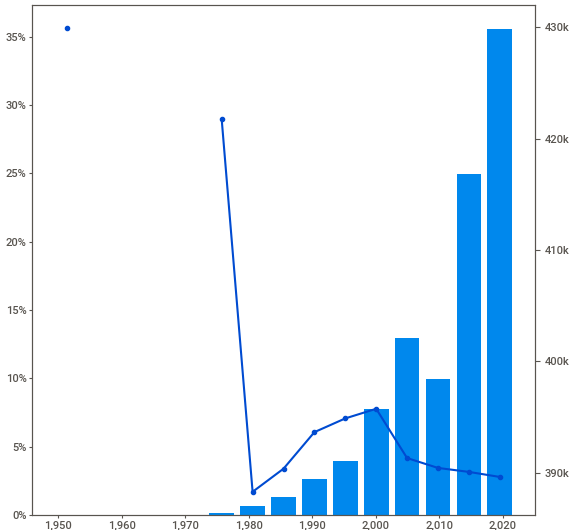
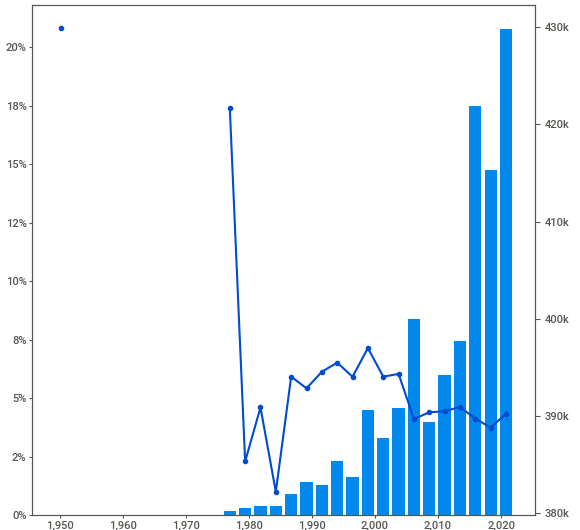
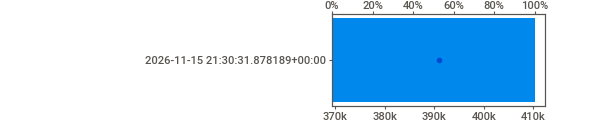
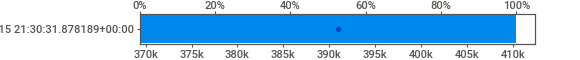
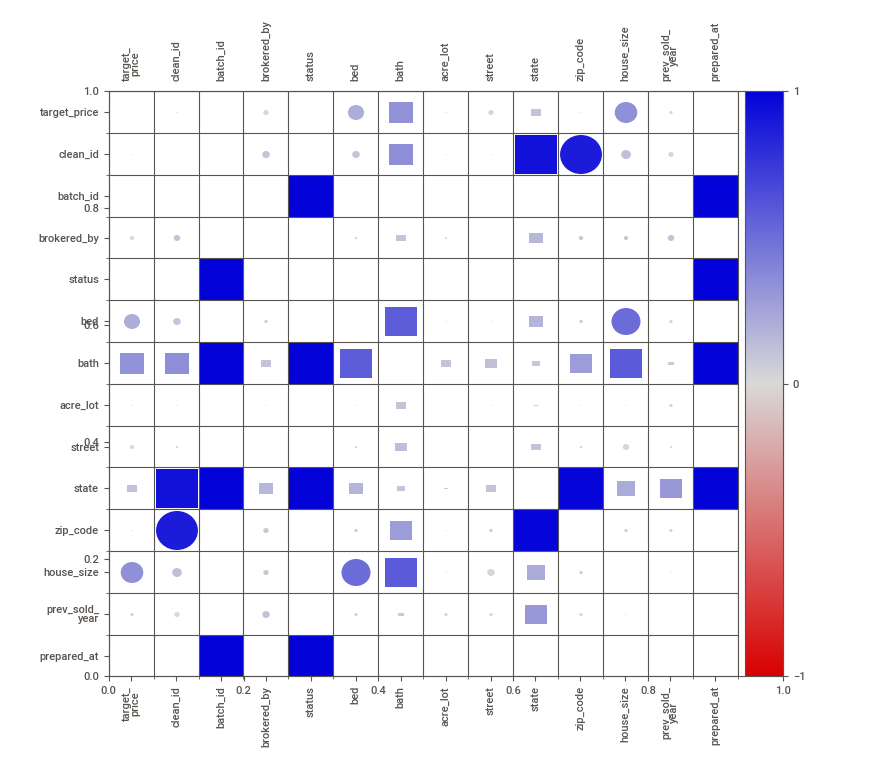
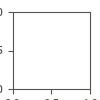

Report reports/eda_baseline_sweetviz.html was generated.


In [3]:
import sweetviz as sv

os.makedirs("reports", exist_ok=True)

eda_report = sv.analyze(
    [gold_baseline, "Gold baseline"],
    target_feat="target_price",
)

eda_report.show_notebook(w=1100, h=900, scale=0.8)
eda_report.show_html(
    filepath="reports/eda_baseline_sweetviz.html",
    open_browser=False,
)

In [4]:
import mlflow

mlflow.set_tracking_uri("http://mlflow:5000")
mlflow.set_experiment("property_price_regression")

with mlflow.start_run(run_name="eda_gold_baseline") as run:
    mlflow.log_params({
        "data_layer": "gold",
        "table": "gold.property_training_features",
        "sample_size": len(gold_baseline),
        "target": "target_price",
        "tool": "sweetviz",
    })

    mlflow.log_metrics({
        "columns": float(gold_baseline.shape[1]),
        "missing_cells": float(gold_baseline.isna().sum().sum()),
        "target_mean": float(gold_baseline["target_price"].mean()),
        "target_std": float(gold_baseline["target_price"].std()),
    })

    mlflow.log_artifact(
        "reports/eda_baseline_sweetviz.html",
        artifact_path="eda",
    )

print("EDA registrado en MLflow")
print("run_id:", run.info.run_id)

2026/11/22 15:14:16 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/22 15:14:17 INFO mlflow.tracking._tracking_service.client: 🏃 View run eda_gold_baseline at: http

EDA registrado en MLflow
run_id: d7437b75989c47438273554a178b3553


In [6]:
import json
import numpy as np
from datetime import datetime, timezone

excluded_columns = {"target_price", "clean_id", "batch_id"}

numeric_columns = [
    col for col in gold_baseline.select_dtypes(include="number").columns
    if col not in excluded_columns
]

categorical_columns = [
    col for col in gold_baseline.select_dtypes(
        include=["object", "category", "bool"]
    ).columns
    if col not in excluded_columns
]

baseline_profile = {
    "created_at": datetime.now(timezone.utc).isoformat(),
    "source_table": "gold.property_training_features",
    "sample_size": len(gold_baseline),
    "target": "target_price",
    "target_summary": gold_baseline["target_price"].describe().to_dict(),
    "numeric_features": {},
    "categorical_features": {},
}

for column in numeric_columns:
    values = gold_baseline[column].dropna()
    if len(values):
        counts, edges = np.histogram(values, bins=10)
        baseline_profile["numeric_features"][column] = {
            "missing_rate": float(gold_baseline[column].isna().mean()),
            "quantiles": values.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).to_dict(),
            "histogram_edges": edges.tolist(),
            "histogram_counts": counts.tolist(),
        }

for column in categorical_columns:
    baseline_profile["categorical_features"][column] = {
        "missing_rate": float(gold_baseline[column].isna().mean()),
        "top_values": gold_baseline[column].fillna("__MISSING__")
        .value_counts(normalize=True)
        .head(30)
        .to_dict(),
    }

with open("reports/baseline_profile.json", "w") as file:
    json.dump(baseline_profile, file, indent=2, default=float)

print("Baseline creado")
print("Numéricas:", list(baseline_profile["numeric_features"]))
print("Categóricas:", list(baseline_profile["categorical_features"]))

Baseline creado
Numéricas: ['brokered_by', 'bed', 'bath', 'acre_lot', 'street', 'zip_code', 'house_size', 'prev_sold_year']
Categóricas: ['status', 'city', 'state']


In [7]:
import mlflow

mlflow.set_tracking_uri("http://mlflow:5000")
mlflow.set_experiment("property_price_regression")

with mlflow.start_run(run_name="eda_and_drift_baseline") as run:
    mlflow.log_params({
        "source_table": "gold.property_training_features",
        "sample_size": len(gold_baseline),
        "target": "target_price",
        "eda_tool": "sweetviz",
    })
    mlflow.log_metrics({
        "feature_count": float(len(numeric_columns) + len(categorical_columns)),
        "target_mean": float(gold_baseline["target_price"].mean()),
        "target_std": float(gold_baseline["target_price"].std()),
    })
    mlflow.log_artifact("reports/eda_baseline_sweetviz.html", artifact_path="eda")
    mlflow.log_artifact("reports/baseline_profile.json", artifact_path="drift")

print("Baseline registrado")
print("run_id:", run.info.run_id)

2026/11/22 15:27:19 INFO mlflow.tracking._tracking_service.client: 🏃 View run eda_and_drift_baseline at: http://mlflow:5000/#/experiments/3/runs/f85398ce09b64713af38c19045e442c2.
2026/11/22 15:27:19 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/3.


Baseline registrado
run_id: f85398ce09b64713af38c19045e442c2
